In [1]:
from langgraph.graph import StateGraph ,START,END
from langchain_groq import ChatGroq
from typing import TypedDict
from  dotenv import load_dotenv

In [2]:
load_dotenv()
model = ChatGroq(
    model="llama-3.1-8b-instant",
    temperature=0.9, 
)

In [3]:
class BatsmanState(StateGraph):
    runs: int
    balls: int
    fours: int
    sixes: int
    
    sr: float
    bpb: float
    boundary_precent: float
    summary: str

In [27]:
def calulate_sr(state: BatsmanState)-> BatsmanState:
    sr = (state['runs']/state['balls'])*100
    return {'sr': sr}

In [21]:
def calulate_bpb(state: BatsmanState)-> BatsmanState:
    bpb= (state['balls']/state['fours']/state['sixes'])
    return {'bpb': bpb}

In [22]:
def calulate_boundary_precent(state: BatsmanState)-> BatsmanState:
    boundary_precent = (((state['fours']*4)+(state['sixes']*6))/state['runs'])*100
    return {'boundary_precent': boundary_precent}
    

In [23]:
def summary(state: BatsmanState)-> BatsmanState:
    summary = f"""
    Strike Rate - {state['sr']}\n
    Balls per boundary - {state['bpb']}
    boundary_precent - {state['boundary_precent']}
    """
 
    return {'summary': summary}

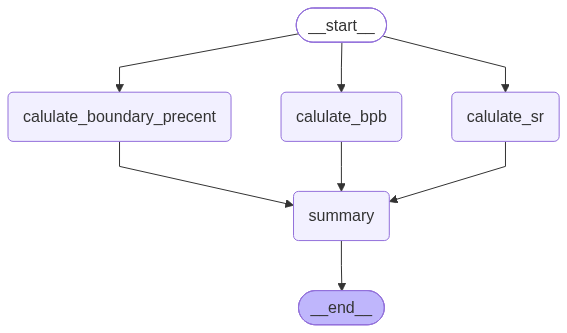

In [28]:
graph= StateGraph(BatsmanState)

graph.add_node('calulate_sr',calulate_sr)
graph.add_node('calulate_bpb',calulate_bpb)
graph.add_node('calulate_boundary_precent',calulate_boundary_precent)
graph.add_node('summary',summary)

graph.add_edge(START, 'calulate_sr')
graph.add_edge(START, 'calulate_bpb')
graph.add_edge(START, 'calulate_boundary_precent')

graph.add_edge('calulate_sr' ,'summary')
graph.add_edge('calulate_bpb' ,'summary')
graph.add_edge('calulate_boundary_precent' ,'summary')

graph.add_edge('summary', END)

workflow  = graph.compile()

workflow

In [29]:
initial_state = {
    'runs':100,
    'balls':50,
    'fours': 6,
    'sixes': 4
}

final_state = workflow.invoke(initial_state)

In [30]:
print(final_state)

{'runs': 100, 'balls': 50, 'fours': 6, 'sixes': 4, 'sr': 200.0, 'bpb': 2.0833333333333335, 'boundary_precent': 48.0, 'summary': '\n    Strike Rate - 200.0\n\n    Balls per boundary - 2.0833333333333335\n    boundary_precent - 48.0\n    '}
